# Comparaison de tous les modèles

Ce notebook relit **tous** les modèles enregistrés (`results/models/`) et les votes de `06_Ensemble_Learning` (`results/models_ensemble/`), puis les compare sous plusieurs angles. Chaque section est indépendante : supprime celles dont tu n'as pas besoin.

| Section | Question |
|---|---|
| 1 | Quelle configuration (jeu de variables, avec ou sans `year`) convient à chaque modèle ? |
| 2 | Quel est l'effet de `year`, modèle par modèle ? |
| 3 | Entraîner sur tout le train améliore-t-il par rapport à l'échantillon ? |
| 4 | Où chaque modèle réussit-il ou échoue-t-il (F1 par classe) ? |
| 5 | Quel est le prix de la performance (temps de prédiction) ? |
| 6 | Le score de validation prédit-il le score de test ? |
| 7 | Les modèles se trompent-ils aux mêmes endroits ? |
| 8 | Les écarts sont-ils réguliers mois par mois ? (test apparié) |
| 9 | Les erreurs sont-elles voisines (Low↔Medium) ou graves (Low↔High) ? |

Les prédictions du test sont calculées une fois puis mises en cache dans `results/predictions_test/`.

In [14]:
import os
import json
import time
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import wilcoxon, spearmanr
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, cohen_kappa_score

BASE = os.environ.get("DM_BASE", r"C:\Users\chahi\Desktop\DM-Weather-framework\data")
# BASE = os.environ.get("DM_BASE", r"D:\M2\Data Mining\DM-Weather-framework\data")
SUP_DIR = os.path.join(BASE, "processed", "transformed", "supervised")
RES_DIR = r"C:\Users\chahi\Desktop\DM-Weather-framework\results"
TABLES_DIR = os.path.join(RES_DIR, "tables")
FIGURES_DIR = os.path.join(RES_DIR, "figures")
MODELES_DIR = os.path.join(RES_DIR, "supervised_models")
ENS_DIR = os.path.join(RES_DIR, "models_ensemble")
PRED_DIR = os.path.join(RES_DIR, "predictions_test")
for d in (TABLES_DIR, FIGURES_DIR, PRED_DIR):
    os.makedirs(d, exist_ok=True)

LABELS = ["Low", "Medium", "High"]
NOMS_FAM = {"knn": "KNN", "svm": "SVM", "rf": "RF", "vote_hard": "Vote hard", "vote_soft": "Vote soft"}
ORDRE_CONFIG = ["complet", "complet_sans_year", "reduit", "reduit_sans_year"]

# ---- Paramètres ----
CONFIG_REF = "reduit_sans_year"    # configuration utilisée pour les sections 7 à 9 (une seule par famille de modèle)
DONNEES_REF = "train_complet"      # "echantillon" ou "train_complet"
RECALCULER = False                 # True = recalcule toutes les prédictions du test

In [15]:
test  = pd.read_parquet(os.path.join(SUP_DIR, "test_supervised.parquet"))
train = pd.read_parquet(os.path.join(SUP_DIR, "train_supervised.parquet"), columns=["classe", "month"])
for d in (train, test):
    d["classe"] = d["classe"].astype(str)
test["date"] = pd.to_datetime(test["date"])
y_test = test["classe"].to_numpy()
print("Test :", test.shape)

Test : (151900, 18)


## Collecte : prédictions et scores de chaque modèle

In [17]:
lignes, PRED = [], {}
META_VIDE = dict(famille="", config="", jeu="", avec_year=None, donnees="", val=None, temps_fit_s=None, temps_pred_s=None)

def ajouter(label, y_pred, **meta):
    y_pred = np.asarray(y_pred, dtype=str)
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=LABELS, zero_division=0)
    ligne = dict(META_VIDE, label=label, accuracy=accuracy_score(y_test, y_pred), macro_F1=f.mean(),
                 F1_Low=f[0], F1_Medium=f[1], F1_High=f[2])
    ligne.update(meta)
    lignes.append(ligne)
    PRED[label] = y_pred

# Baselines (calculées sur le train)
ajouter("Baseline : classe majoritaire", np.full(len(y_test), train["classe"].mode()[0]), famille="baseline")
par_mois = train.groupby("month")["classe"].agg(lambda s: s.mode()[0])
ajouter("Baseline : classe majoritaire par mois", test["month"].map(par_mois).to_numpy(), famille="baseline")

# KNN, SVM, RF : tous les modèles enregistrés
for chemin_json in sorted(glob.glob(os.path.join(MODELES_DIR, "*", "*.json"))):
    with open(chemin_json, encoding="utf-8") as f:
        fiche = json.load(f)
    famille = fiche.get("modele")

    if famille is None:
        nom_modele = fiche.get("nom", os.path.splitext(os.path.basename(chemin_json))[0])
        famille = next(
            (fam for fam in NOMS_FAM if nom_modele.lower().startswith(fam + "_")),
            None,
        )

    if famille not in NOMS_FAM:
        print("Modèle ignoré (famille inconnue) :", chemin_json)
        continue

    fiche["modele"] = famille
    label = NOMS_FAM[famille] + " | " + fiche["config"] + " | " + fiche["donnees"]
    cache = os.path.join(PRED_DIR, fiche["config"] + "__" + fiche["nom"] + ".npz")
    if os.path.exists(cache) and not RECALCULER:
        c = np.load(cache)
        y_pred, temps = c["pred"], float(c["temps"])
    else:
        modele = joblib.load(os.path.splitext(chemin_json)[0] + ".pkl")
        t0 = time.time()
        y_pred = np.asarray(modele.predict(test[fiche["variables"]]), dtype=str)
        temps = round(time.time() - t0, 1)
        np.savez(cache, pred=y_pred, temps=temps)
        print(label, ": prédit en", temps, "s")
    ajouter(label, y_pred, famille=fiche["modele"], config=fiche["config"], jeu=fiche["jeu"],
            avec_year=fiche["avec_year"], donnees=fiche["donnees"], val=fiche.get("macro_F1_validation"),
            temps_fit_s=fiche.get("temps_fit_s"), temps_pred_s=temps)

# Votes hard et soft (produits par 06_Ensemble_Learning)
for chemin in sorted(glob.glob(os.path.join(ENS_DIR, "*", "votes_test_*.npz"))):
    config = os.path.basename(os.path.dirname(chemin))
    donnees = os.path.basename(chemin)[len("votes_test_"):-len(".npz")]
    c = np.load(chemin)
    for cle, famille in (("hard", "vote_hard"), ("soft", "vote_soft")):
        ajouter(NOMS_FAM[famille] + " | " + config + " | " + donnees, c[cle], famille=famille, config=config,
                jeu=config.replace("_sans_year", ""), avec_year=not config.endswith("_sans_year"), donnees=donnees)

df = pd.DataFrame(lignes)
chemin_csv = os.path.join(TABLES_DIR, "test", "comparaison_modeles.csv")
os.makedirs(os.path.dirname(chemin_csv), exist_ok=True)
df.drop(columns=[]).round(4).to_csv(chemin_csv, index=False)
print(len(df), "lignes (baselines comprises). Tableau enregistré :", chemin_csv)
display(df[["label", "accuracy", "macro_F1", "F1_Low", "F1_Medium", "F1_High", "val", "temps_pred_s"]]
        .sort_values("macro_F1", ascending=False).round(4).reset_index(drop=True))

KNN | reduit_sans_year | echantillon : prédit en 10.0 s
KNN | reduit_sans_year | train_complet : prédit en 195.8 s
RF | reduit_sans_year | echantillon : prédit en 0.7 s
RF | reduit_sans_year | train_complet : prédit en 0.7 s
SVM | reduit_sans_year | echantillon : prédit en 96.1 s
SVM | reduit_sans_year | train_complet : prédit en 251.0 s
26 lignes (baselines comprises). Tableau enregistré : C:\Users\chahi\Desktop\DM-Weather-framework\results\tables\test\comparaison_modeles.csv


,label,accuracy,macro_F1,F1_Low,F1_Medium,F1_High,val,temps_pred_s
0,SVM | reduit_sans_year | echantillon,0.8995,0.8860,0.8485,0.8688,0.9406,0.8644,96.1
1,SVM | complet_sans_year | train_complet,0.9013,0.8857,0.8423,0.8693,0.9455,0.8653,253.2
2,SVM | complet_sans_year | echantillon,0.8995,0.8857,0.8474,0.8686,0.9411,0.8653,81.9
3,SVM | reduit_sans_year | train_complet,0.8993,0.8834,0.8395,0.8662,0.9445,0.8644,251.0
4,KNN | reduit_sans_year | echantillon,0.8957,0.8759,0.8194,0.8689,0.9393,0.8410,10.0
5,KNN | complet_sans_year | echantillon,0.8937,0.8733,0.8153,0.8665,0.9382,0.8377,9.6
6,RF | reduit_sans_year | echantillon,0.8908,0.8710,0.8126,0.8644,0.9361,0.8698,0.7
7,RF | reduit_sans_year | train_complet,0.8890,0.8693,0.8105,0.8604,0.9369,0.8698,0.7
8,KNN | complet_sans_year | train_complet,0.8916,0.8675,0.7968,0.8636,0.9421,0.8377,199.5
9,RF | complet_sans_year | echantillon,0.8833,0.8657,0.8149,0.8496,0.9325,0.8661,0.5


In [18]:
def court(label):
    return "Base. par mois" if "par mois" in label else ("Base. majoritaire" if label.startswith("Baseline") else label.split(" | ")[0])

def heatmap(table, titre, fichier, fmt="{:.3f}", cmap="viridis", centre_zero=False):
    vals = table.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(1.5 * table.shape[1] + 4, 0.45 * table.shape[0] + 2))
    if centre_zero:
        m = np.nanmax(np.abs(vals)) or 1.0
        im = ax.imshow(vals, cmap="RdBu", vmin=-m, vmax=m, aspect="auto")
    else:
        im = ax.imshow(vals, cmap=cmap, aspect="auto")
    ax.set_xticks(range(table.shape[1])); ax.set_xticklabels(table.columns, rotation=30, ha="right")
    ax.set_yticks(range(table.shape[0])); ax.set_yticklabels(table.index)
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            if not np.isnan(vals[i, j]):
                r, g, b, _ = im.cmap(im.norm(vals[i, j]))
                ax.text(j, i, fmt.format(vals[i, j]), ha="center", va="center", fontsize=8,
                        color="black" if 0.299 * r + 0.587 * g + 0.114 * b > 0.5 else "white")
    ax.set_title(titre)
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, fichier), dpi=150, bbox_inches="tight")
    plt.show()

modeles = df[df["famille"].isin(NOMS_FAM)].copy()
m3 = df[df["famille"].isin(["knn", "svm", "rf"])].copy()

## 1. Quelle configuration pour quel modèle ? (macro-F1 sur le test)

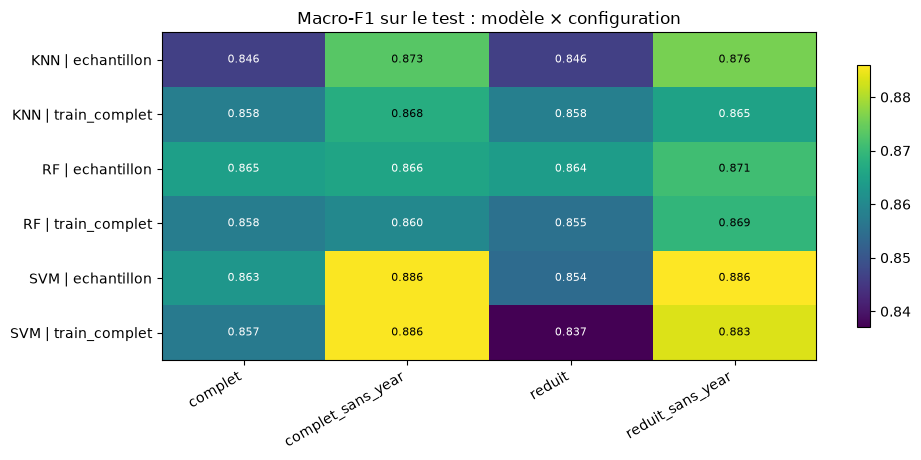

In [19]:
modeles["ligne"] = modeles["famille"].map(NOMS_FAM) + " | " + modeles["donnees"]
tab = modeles.pivot_table(index="ligne", columns="config", values="macro_F1")
tab = tab.reindex(columns=[c for c in ORDRE_CONFIG if c in tab.columns])
heatmap(tab, "Macro-F1 sur le test : modèle × configuration", "cmp_1_macroF1_config.png")

## 2. Effet de `year`

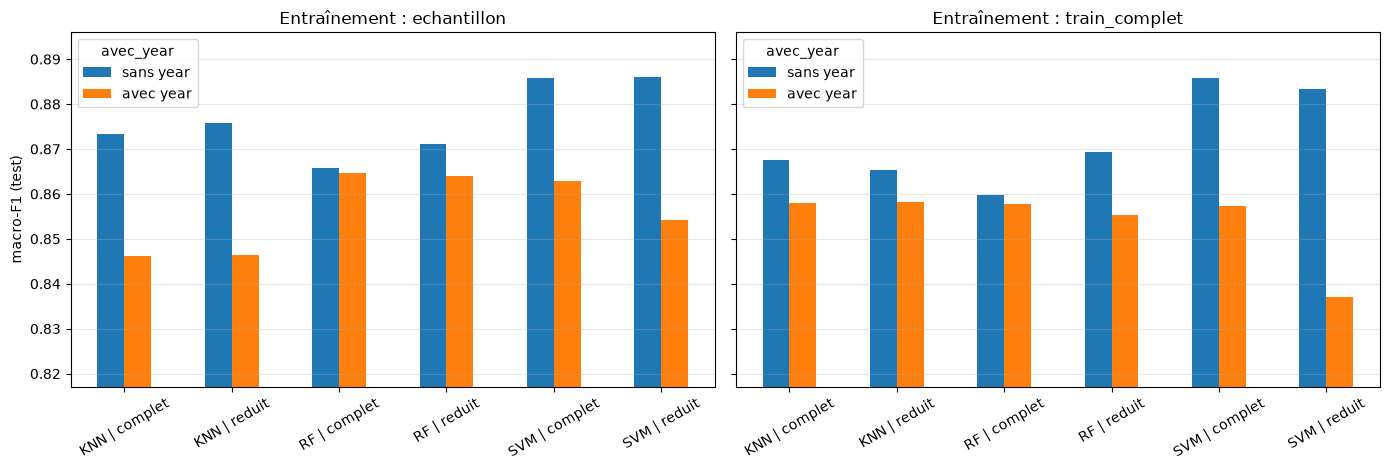

groupe                 KNN | complet  KNN | reduit  RF | complet  RF | reduit  SVM | complet  SVM | reduit
gain en retirant year         0.0271        0.0295        0.0009        0.007         0.0229        0.0318
groupe                 KNN | complet  KNN | reduit  RF | complet  RF | reduit  SVM | complet  SVM | reduit
gain en retirant year         0.0095        0.0072         0.002       0.0141         0.0284        0.0464


In [20]:
m3["groupe"] = m3["famille"].map(NOMS_FAM) + " | " + m3["jeu"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
tous = []
for ax, donnees in zip(axes, ["echantillon", "train_complet"]):
    t = m3[m3["donnees"] == donnees].pivot_table(index="groupe", columns="avec_year", values="macro_F1")
    t = t.rename(columns={True: "avec year", False: "sans year"})
    if not t.empty:
        t.plot.bar(ax=ax, rot=30)
        tous.append(t)
    ax.set_title("Entraînement : " + donnees); ax.set_xlabel(""); ax.grid(axis="y", alpha=0.3)
if tous:
    bas = min(t.min().min() for t in tous)
    axes[0].set_ylim(bas - 0.02, max(t.max().max() for t in tous) + 0.01)
axes[0].set_ylabel("macro-F1 (test)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "cmp_2_effet_year.png"), dpi=150, bbox_inches="tight")
plt.show()

for t in tous:
    if {"avec year", "sans year"} <= set(t.columns):
        print((t["sans year"] - t["avec year"]).round(4).rename("gain en retirant year").to_frame().T.to_string())

## 3. Échantillon (30 000 lignes) contre train complet

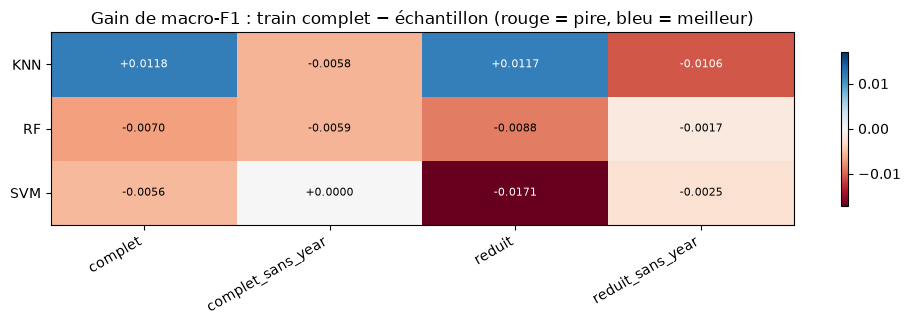

Gain moyen : -0.0035


In [21]:
t = m3.pivot_table(index=["famille", "config"], columns="donnees", values="macro_F1")
if {"echantillon", "train_complet"} <= set(t.columns):
    delta = (t["train_complet"] - t["echantillon"]).unstack("config")
    delta.index = [NOMS_FAM[i] for i in delta.index]
    delta = delta.reindex(columns=[c for c in ORDRE_CONFIG if c in delta.columns])
    heatmap(delta, "Gain de macro-F1 : train complet − échantillon (rouge = pire, bleu = meilleur)",
            "cmp_3_echantillon_vs_complet.png", fmt="{:+.4f}", centre_zero=True)
    print("Gain moyen :", round(float(np.nanmean(delta.to_numpy())), 4))
else:
    print("Il faut des modèles entraînés sur l'échantillon ET sur le train complet.")

## 4. F1 par classe

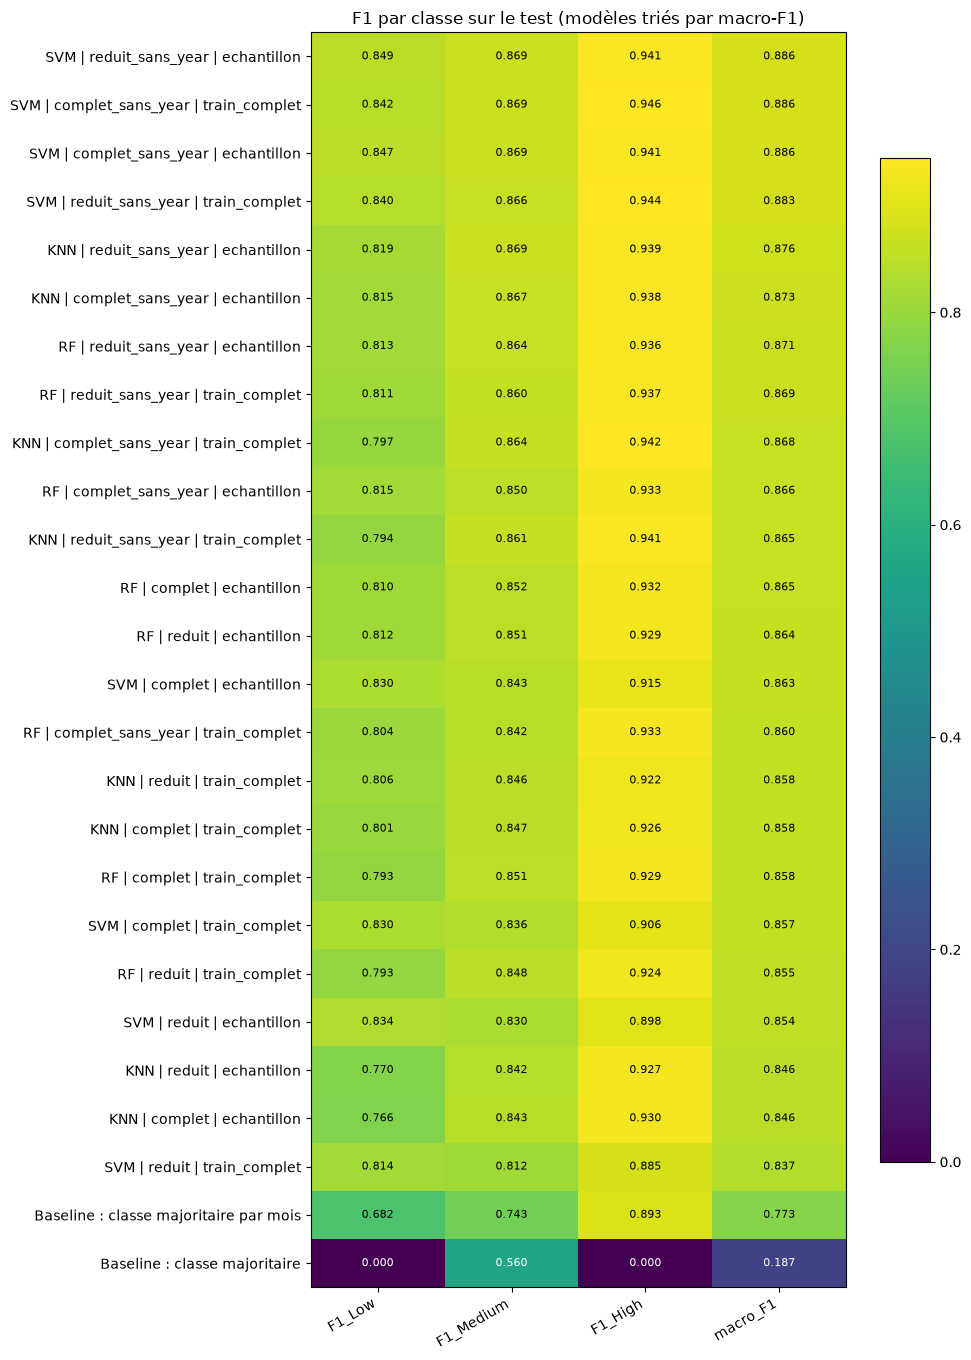

In [22]:
tab = df.set_index("label")[["F1_Low", "F1_Medium", "F1_High", "macro_F1"]].sort_values("macro_F1", ascending=False)
heatmap(tab, "F1 par classe sur le test (modèles triés par macro-F1)", "cmp_4_F1_par_classe.png")

## 5. Performance contre coût

Temps de prédiction sur tout le test (échelle logarithmique). KNN et SVM sur le train complet sont bien plus lents que le Random Forest.

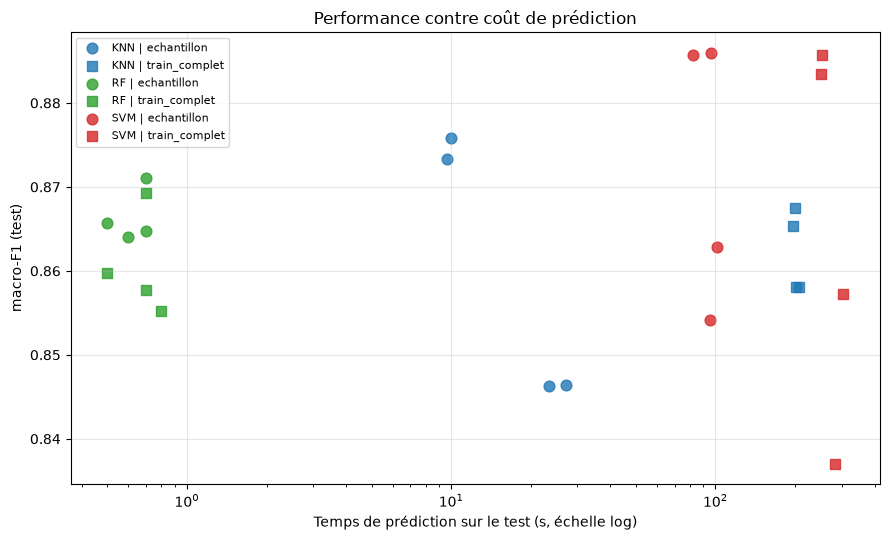

In [23]:
x = m3.dropna(subset=["temps_pred_s"])
couleurs = {"knn": "tab:blue", "svm": "tab:red", "rf": "tab:green"}
marqueurs = {"echantillon": "o", "train_complet": "s"}
fig, ax = plt.subplots(figsize=(9, 5.5))
for (fam, don), g in x.groupby(["famille", "donnees"]):
    ax.scatter(g["temps_pred_s"], g["macro_F1"], c=couleurs[fam], marker=marqueurs[don], s=60,
               alpha=0.8, label=NOMS_FAM[fam] + " | " + don)
ax.set_xscale("log")
ax.set_xlabel("Temps de prédiction sur le test (s, échelle log)")
ax.set_ylabel("macro-F1 (test)")
ax.set_title("Performance contre coût de prédiction")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "cmp_5_performance_cout.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Validation contre test

Si le classement en validation (3 plis chronologiques sur l'échantillon) prédisait bien le classement sur le test, choisir un modèle sur la validation serait fiable. On ne garde que les modèles entraînés sur l'échantillon, dont le score de validation leur est propre.

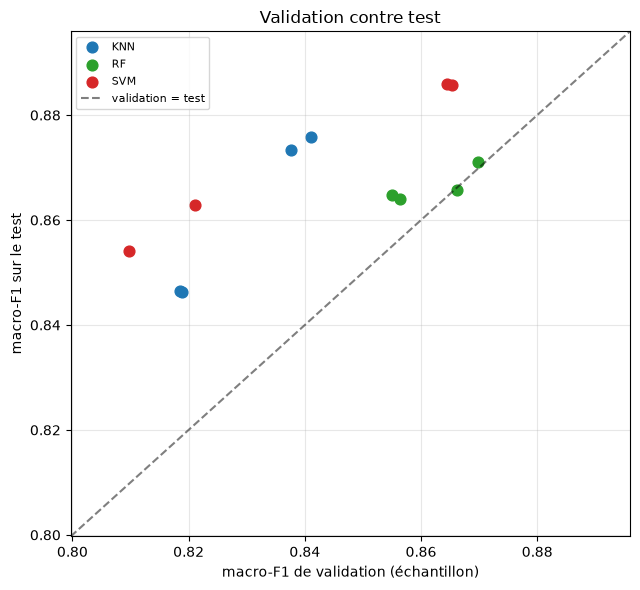

Corrélation de rang (Spearman) validation / test : 0.68 (p = 0.015, 12 modèles)


In [24]:
v = df[(df["donnees"] == "echantillon") & df["val"].notna()]
if len(v) >= 3:
    fig, ax = plt.subplots(figsize=(6.5, 6))
    for fam, g in v.groupby("famille"):
        ax.scatter(g["val"], g["macro_F1"], c=couleurs[fam], s=60, label=NOMS_FAM[fam])
    lim = [min(v["val"].min(), v["macro_F1"].min()) - 0.01, max(v["val"].max(), v["macro_F1"].max()) + 0.01]
    ax.plot(lim, lim, "k--", alpha=0.5, label="validation = test")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("macro-F1 de validation (échantillon)"); ax.set_ylabel("macro-F1 sur le test")
    ax.set_title("Validation contre test"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_DIR, "cmp_6_validation_vs_test.png"), dpi=150, bbox_inches="tight")
    plt.show()
    rho, p = spearmanr(v["val"], v["macro_F1"])
    print(f"Corrélation de rang (Spearman) validation / test : {rho:.2f} (p = {p:.3f}, {len(v)} modèles)")
else:
    print("Pas assez de modèles entraînés sur l'échantillon.")

## 7. Accord entre les modèles

Pour les sections 7 à 9, on compare un modèle par famille dans la configuration de référence (`CONFIG_REF`, `DONNEES_REF`), plus la baseline par mois. Cette sélection est fixée à l'avance, pas choisie sur le test.

Modèles comparés : ['KNN | reduit_sans_year | train_complet', 'SVM | reduit_sans_year | train_complet', 'RF | reduit_sans_year | train_complet', 'Baseline : classe majoritaire par mois']


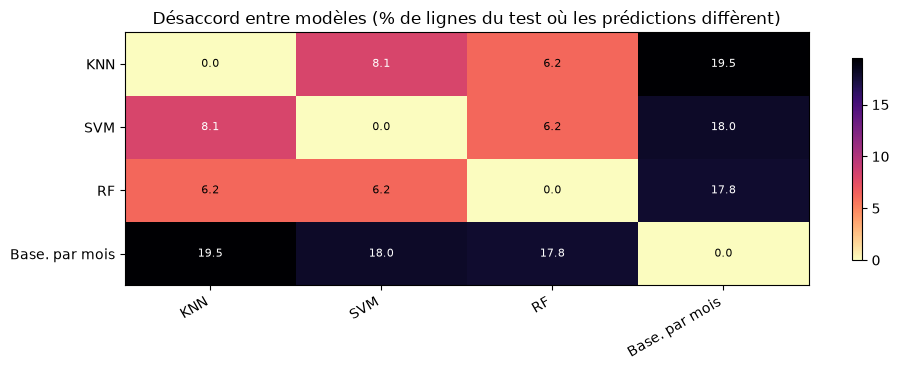

In [25]:
suffixe = " | " + CONFIG_REF + " | " + DONNEES_REF
SELECTION = [NOMS_FAM[f] + suffixe for f in ("knn", "svm", "rf", "vote_hard", "vote_soft")]
SELECTION = [s for s in SELECTION if s in PRED] + ["Baseline : classe majoritaire par mois"]
print("Modèles comparés :", SELECTION)

noms_courts = [court(s) for s in SELECTION]
M = np.array([[(PRED[a] != PRED[b]).mean() * 100 for b in SELECTION] for a in SELECTION])
heatmap(pd.DataFrame(M, index=noms_courts, columns=noms_courts),
        "Désaccord entre modèles (% de lignes du test où les prédictions diffèrent)",
        "cmp_7_desaccord.png", fmt="{:.1f}", cmap="magma_r")

## 8. Test apparié mois par mois

On compare l'accuracy de chaque mois du test (28 mois) entre un modèle et la référence `REF_STAT`. Les lignes d'un même mois sont fortement corrélées entre elles : c'est le **mois** qui est l'unité d'observation, pas la ligne. Le test de Wilcoxon (apparié) répond à : « le modèle est-il meilleur de façon régulière, ou juste en moyenne ? ». Avec 28 mois, un petit écart ne sera jamais significatif.

In [26]:
REF_STAT = "SVM" + suffixe
if REF_STAT not in PRED:
    REF_STAT = SELECTION[0]
dates = test["date"].to_numpy()

def acc_par_mois(y_pred):
    return pd.Series(y_pred == y_test).groupby(dates).mean()

ref = acc_par_mois(PRED[REF_STAT])
stat = []
for s in SELECTION:
    if s == REF_STAT:
        continue
    d = acc_par_mois(PRED[s]) - ref
    try:
        p = wilcoxon(d).pvalue
    except ValueError:        # tous les écarts sont nuls
        p = np.nan
    stat.append({"modele": court(s), "ecart_moyen_accuracy": d.mean(), "mois_meilleurs": int((d > 0).sum()),
                 "mois_pires": int((d < 0).sum()), "n_mois": len(d), "p_wilcoxon": p})
print("Référence :", REF_STAT)
display(pd.DataFrame(stat).round(4))

Référence : SVM | reduit_sans_year | train_complet


,modele,ecart_moyen_accuracy,mois_meilleurs,mois_pires,n_mois,p_wilcoxon
0,KNN,-0.0097,12,15,28,0.4279
1,RF,-0.0103,15,13,28,0.9375
2,Base. par mois,-0.0912,5,23,28,0.0004


## 9. Gravité des erreurs

Les classes sont ordonnées (Low < Medium < High). Se tromper d'une classe voisine est moins grave que prédire High pour un mois Low. On compte les deux types d'erreurs et on calcule le **kappa quadratique pondéré** (1 = parfait, 0 = hasard), qui pénalise davantage les erreurs graves.

,label,erreurs_voisines_%,erreurs_Low_High_%,kappa_quadratique
0,SVM | complet_sans_year | train_complet,9.868,0.0,0.905
1,SVM | reduit_sans_year | train_complet,10.074,0.0,0.903
2,SVM | complet_sans_year | echantillon,10.046,0.0,0.902
3,SVM | reduit_sans_year | echantillon,10.045,0.0,0.902
4,KNN | reduit_sans_year | echantillon,10.434,0.0,0.893
5,KNN | complet_sans_year | echantillon,10.633,0.0,0.890
6,KNN | complet_sans_year | train_complet,10.837,0.0,0.889
7,RF | reduit_sans_year | train_complet,11.100,0.0,0.888
8,RF | reduit_sans_year | echantillon,10.917,0.0,0.888
9,KNN | reduit_sans_year | train_complet,11.044,0.0,0.887


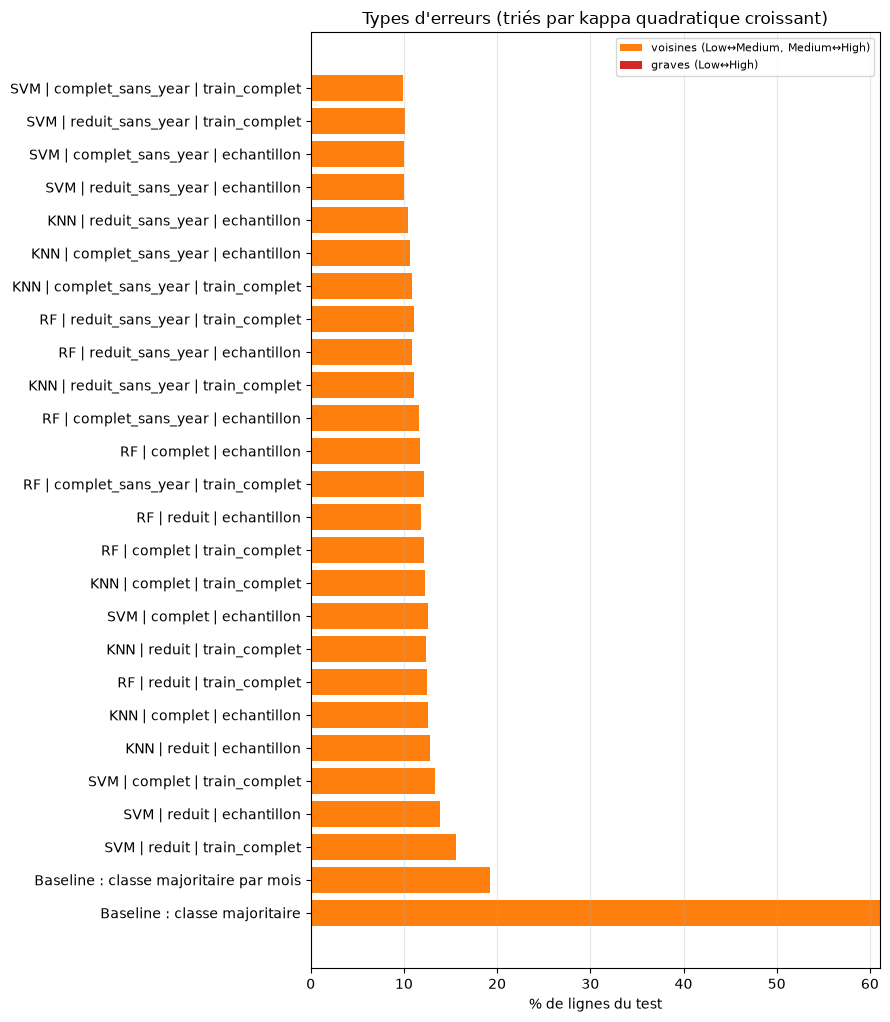

In [27]:
idx = {c: i for i, c in enumerate(LABELS)}
yt = pd.Series(y_test).map(idx).to_numpy()
lignes_o = []
for label, y_pred in PRED.items():
    yp = pd.Series(y_pred).map(idx).to_numpy()
    ecart = np.abs(yt - yp)
    lignes_o.append({"label": label, "erreurs_voisines_%": (ecart == 1).mean() * 100,
                     "erreurs_Low_High_%": (ecart == 2).mean() * 100,
                     "kappa_quadratique": cohen_kappa_score(yt, yp, weights="quadratic")})
o = pd.DataFrame(lignes_o).sort_values("kappa_quadratique").reset_index(drop=True)
display(o.sort_values("kappa_quadratique", ascending=False).round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 0.32 * len(o) + 2))
ax.barh(o["label"], o["erreurs_voisines_%"], label="voisines (Low↔Medium, Medium↔High)", color="tab:orange")
ax.barh(o["label"], o["erreurs_Low_High_%"], left=o["erreurs_voisines_%"], label="graves (Low↔High)", color="tab:red")
ax.set_xlabel("% de lignes du test"); ax.set_title("Types d'erreurs (triés par kappa quadratique croissant)")
ax.legend(fontsize=8); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "cmp_9_gravite_erreurs.png"), dpi=150, bbox_inches="tight")
plt.show()